# Real-world Data Wrangling: Economic Growth and Equity Prices

## 1. Gather data

### 1.1 Problem statement
Economic growth and stock-market movements may be related, but the direction and strength of their association are not obvious. This project combines the World Bank's annual real GDP growth and S&P Global Equity Indices annual percentage change by economy and year for 2000–2023. It examines whether economies with faster real GDP growth tend to have higher stock-index price changes in the same year; the analysis is descriptive and cannot establish causation.

The equity indicator measures **US-dollar price changes**, not total returns, and exchange rates may affect the comparison. The analysis uses available reporting economies, not a representative sample of every country.

### Reproducibility
Run the cells in order from this notebook's folder with Python 3, Jupyter, pandas, matplotlib, and numpy installed. The submitted `raw/` files are cached so the notebook runs without a network connection; set `REFRESH_RAW = True` to retrieve fresh World Bank data (which may have changed). Raw responses are preserved before any cleaning; the cleaned CSV is written separately to `cleaned/`. The extraction uses the World Bank's country metadata distributed alongside the GDP file to exclude regional and income-group aggregates.

In [1]:
from pathlib import Path
from io import BytesIO
import json
import zipfile
from urllib.parse import urlencode
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 12)
plt.style.use("ggplot")
RAW = Path("raw")
CLEAN = Path("cleaned")
RAW.mkdir(exist_ok=True)
CLEAN.mkdir(exist_ok=True)
REFRESH_RAW = False
START_YEAR, END_YEAR = 2000, 2023

### 1.2 Dataset 1: GDP growth
I chose [GDP growth (annual %), NY.GDP.MKTP.KD.ZG](https://data.worldbank.org/indicator/NY.GDP.MKTP.KD.ZG) to measure changes in real economic output rather than the size of an economy. The gathering method is **programmatically downloading a bulk CSV ZIP file** from the World Bank; the original ZIP and its country metadata are saved intact. Its country name and country code identify the economy, and its year columns contain GDP growth percentages, providing country-year observations for the comparison.

A GDP sample is one country-year measurement, not one row of the raw wide table: each raw row contains one country or aggregate with 24 separate year columns for 2000–2023. The cell below counts both all country-year positions and non-missing GDP measurements, demonstrating that there are more than 500 observations; the later reshape gives each country-year its own row.

In [2]:
gdp_url = "https://api.worldbank.org/v2/en/indicator/NY.GDP.MKTP.KD.ZG?downloadformat=csv"
gdp_archive = RAW / "world_bank_gdp_growth_bulk_csv.zip"

if REFRESH_RAW or not gdp_archive.exists():
    with urlopen(gdp_url, timeout=120) as response:
        gdp_archive.write_bytes(response.read())

with zipfile.ZipFile(gdp_archive) as archive:
    # Read the indicator and metadata directly; keep the downloaded ZIP untouched.
    data_names = [name for name in archive.namelist()
                  if name.startswith("API_") and name.endswith(".csv")]
    metadata_names = [name for name in archive.namelist()
                      if name.startswith("Metadata_Country_") and name.endswith(".csv")]
    if len(data_names) != 1 or len(metadata_names) != 1:
        raise ValueError("Expected one indicator CSV and one country metadata CSV in the World Bank archive.")
    gdp_raw = pd.read_csv(BytesIO(archive.read(data_names[0])), skiprows=4)
    countries_raw = pd.read_csv(BytesIO(archive.read(metadata_names[0])))

year_columns = [str(year) for year in range(START_YEAR, END_YEAR + 1)]
if not set(year_columns).issubset(gdp_raw.columns):
    raise ValueError("The bulk file does not contain every requested year.")
print("GDP source:", gdp_url)
print("GDP wide table:", gdp_raw.shape, "| country-year values in period:",
      gdp_raw[year_columns].size, "| non-missing values:",
      int(gdp_raw[year_columns].notna().sum().sum()))
assert gdp_raw[year_columns].notna().sum().sum() > 500
display(gdp_raw[["Country Name", "Country Code", *year_columns[:4]]].head())

GDP source: https://api.worldbank.org/v2/en/indicator/NY.GDP.MKTP.KD.ZG?downloadformat=csv
GDP wide table: (266, 71) | country-year values in period: 6384 | non-missing values: 6120


,Country Name,Country Code,2000,2001,2002,2003
0,Aruba,ABW,7.622921,4.182002,-0.944953,1.110505
1,Africa Eastern and Southern,AFE,3.180947,3.503347,3.916848,3.009269
2,Afghanistan,AFG,NaN,-9.431974,28.600001,8.832278
3,Africa Western and Central,AFW,3.811943,5.248525,9.943096,5.626390
4,Angola,AGO,3.054624,4.205999,13.665689,3.487312


### Dataset 2: Equity-index price change
I chose [S&P Global Equity Indices (annual % change), CM.MKT.INDX.ZG](https://data.worldbank.org/indicator/CM.MKT.INDX.ZG), because its country and year keys allow it to be matched to GDP growth and its value measures stock-index price changes. The gathering method is **accessing the World Bank Indicators API**, using JSON responses and pagination; all raw response pages are saved locally before cleaning. The variables are `countryiso3code` (economy), `country.value` (name), `date` (year), and `value` (annual US-dollar equity-index price change, percent).

In [3]:
equity_base = "https://api.worldbank.org/v2/country/all/indicator/CM.MKT.INDX.ZG"
equity_cache = RAW / "world_bank_equity_index_api_pages.json"
params = {"date": f"{START_YEAR}:{END_YEAR}", "format": "json", "per_page": 20000}

if REFRESH_RAW or not equity_cache.exists():
    # Save every page in its original API response structure.
    pages = []
    page_number = 1
    while True:
        url = equity_base + "?" + urlencode({**params, "page": page_number})
        with urlopen(url, timeout=120) as response:
            page = json.load(response)
        if not isinstance(page, list) or len(page) != 2 or not isinstance(page[1], list):
            raise ValueError(f"Unexpected World Bank response for page {page_number}: {page}")
        pages.append(page)
        if page_number >= int(page[0]["pages"]):
            break
        page_number += 1
    equity_cache.write_text(json.dumps(pages, ensure_ascii=False, indent=2), encoding="utf-8")

pages = json.loads(equity_cache.read_text(encoding="utf-8"))
equity_raw = pd.DataFrame([record for page in pages for record in page[1]])
assert len(equity_raw) == int(pages[0][0]["total"])
assert len(equity_raw) > 500 and equity_raw["value"].notna().sum() > 500
print("Equity API:", equity_base, "| parameters:", params)
print("API source last updated:", pages[0][0].get("lastupdated"))
print("Raw equity country-year records:", len(equity_raw),
      "| non-missing values:", equity_raw["value"].notna().sum())
display(equity_raw[["country", "countryiso3code", "date", "value"]].head())

Equity API: https://api.worldbank.org/v2/country/all/indicator/CM.MKT.INDX.ZG | parameters: {'date': '2000:2023', 'format': 'json', 'per_page': 20000}
API source last updated: 2026-11-11
Raw equity country-year records: 6384 | non-missing values: 1893


,country,countryiso3code,date,value
0,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2023,NaN
1,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2022,NaN
2,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2021,NaN
3,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2020,NaN
4,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2019,NaN


## 2. Assess data

Each issue is inspected both visually and programmatically. We inspect examples to understand what the source actually contains and count all affected records to measure its scope; a preview alone cannot establish prevalence.

### Quality issue 1: missing equity country codes
Some equity API records have blank or missing `countryiso3code` values, so they cannot be matched reliably to a GDP country-year using the chosen key. The preview shows the affected records, and counts measure how many records and non-missing index values would be excluded; both views are needed because a few examples cannot show the full impact. These records are income-group or unclassified aggregates, not individual economies, but the missing join key is a genuine completeness issue.

In [4]:
missing_equity_code = equity_raw["countryiso3code"].isna() | equity_raw["countryiso3code"].str.strip().eq("")
display(equity_raw.loc[missing_equity_code, ["country", "countryiso3code", "date", "value"]].head(8))
print("Equity records with missing or blank ISO3 code:", int(missing_equity_code.sum()))
print("Affected records with non-missing equity values:",
      int(equity_raw.loc[missing_equity_code, "value"].notna().sum()))
print("Affected labels:", sorted({item["value"] for item in equity_raw.loc[missing_equity_code, "country"]}))
assert missing_equity_code.any()

,country,countryiso3code,date,value
384,"{'id': 'XD', 'value': 'High income'}",,2023,NaN
385,"{'id': 'XD', 'value': 'High income'}",,2022,NaN
386,"{'id': 'XD', 'value': 'High income'}",,2021,NaN
387,"{'id': 'XD', 'value': 'High income'}",,2020,NaN
388,"{'id': 'XD', 'value': 'High income'}",,2019,NaN
389,"{'id': 'XD', 'value': 'High income'}",,2018,NaN
390,"{'id': 'XD', 'value': 'High income'}",,2017,NaN
391,"{'id': 'XD', 'value': 'High income'}",,2016,NaN


Equity records with missing or blank ISO3 code: 120
Affected records with non-missing equity values: 0
Affected labels: ['High income', 'Low income', 'Lower middle income', 'Not classified', 'Upper middle income']


### Quality issue 2: incomplete indicator values
Missing measurements are not zero and would distort the comparison if treated as observations. The API preview makes the nulls visible, while counts cover both indicators and establish how much data is missing over the chosen period.

In [5]:
display(equity_raw.loc[equity_raw["value"].isna(),
                       ["country", "countryiso3code", "date", "value"]].head(8))
display(gdp_raw.loc[gdp_raw[year_columns[:4]].isna().any(axis=1),
                    ["Country Name", "Country Code", *year_columns[:4]]].head(8))
print("Missing equity values:", int(equity_raw["value"].isna().sum()), "of", len(equity_raw))
print("Missing GDP values:", int(gdp_raw[year_columns].isna().sum().sum()),
      "of", gdp_raw[year_columns].size)
assert equity_raw["value"].isna().any()
assert gdp_raw[year_columns].isna().any().any()

,country,countryiso3code,date,value
0,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2023,NaN
1,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2022,NaN
2,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2021,NaN
3,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2020,NaN
4,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2019,NaN
5,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2018,NaN
6,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2017,NaN
7,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2016,NaN


,Country Name,Country Code,2000,2001,2002,2003
2,Afghanistan,AFG,NaN,-9.431974,28.600001,8.832278
11,American Samoa,ASM,NaN,NaN,NaN,0.965517
38,Channel Islands,CHI,NaN,NaN,NaN,NaN
51,Curacao,CUW,NaN,-0.695754,0.397065,0.288187
52,Cayman Islands,CYM,NaN,NaN,NaN,NaN
56,Djibouti,DJI,NaN,NaN,NaN,NaN
78,Faroe Islands,FRO,NaN,NaN,NaN,NaN
84,Gibraltar,GIB,NaN,NaN,NaN,NaN


Missing equity values: 4491 of 6384
Missing GDP values: 264 of 6384


### Tidiness issue 1: GDP years are column headers
In the bulk file, year is spread across many columns, so one row contains many country-year observations. A column preview shows the structure and a programmatic count confirms the repeated year columns; a long table allows matching on an explicit year variable.

In [6]:
display(gdp_raw[["Country Name", "Country Code", *year_columns[:5]]].head(3))
print("Year columns in study period:", len(year_columns), "| first and last:",
      year_columns[0], year_columns[-1])
assert len(year_columns) > 1

,Country Name,Country Code,2000,2001,2002,2003,2004
0,Aruba,ABW,7.622921,4.182002,-0.944953,1.110505,7.293728
1,Africa Eastern and Southern,AFE,3.180947,3.503347,3.916848,3.009269,5.634682
2,Afghanistan,AFG,NaN,-9.431974,28.600001,8.832278,1.414118


Year columns in study period: 24 | first and last: 2000 2023


### Tidiness issue 2: nested API country fields
The API puts both a country identifier and name inside a dictionary in the `country` column. A visual sample shows the nested structure and a type count checks the entire column; extracting the name into its own column makes the table usable without unpacking objects during analysis.

In [7]:
display(equity_raw[["country", "countryiso3code", "date", "value"]].head(5))
print("Country-field types:")
display(equity_raw["country"].map(lambda value: type(value).__name__).value_counts())
assert equity_raw["country"].map(lambda value: isinstance(value, dict) and "value" in value).all()

,country,countryiso3code,date,value
0,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2023,NaN
1,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2022,NaN
2,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2021,NaN
3,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2020,NaN
4,"{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2019,NaN


Country-field types:


country
dict    6384
Name: count, dtype: int64

## 3. Clean data
We first reshape and unpack the data, then filter the two quality problems; this order makes each country-year observation explicit before missing values are removed. Copies protect the raw frames, and the original files remain unchanged.

### Tidiness issue 1: reshape GDP years
Melting only the study years creates one row per economy and year without changing the underlying values. We retain only the identifier and observation fields needed for the merge; indicator labels and other years are not required for this question.

In [8]:
gdp = gdp_raw.copy().melt(
    id_vars=["Country Name", "Country Code"], value_vars=year_columns,
    var_name="year", value_name="gdp_growth_pct")
gdp = gdp.rename(columns={"Country Name": "country", "Country Code": "country_code"})
gdp["year"] = pd.to_numeric(gdp["year"], errors="raise").astype(int)
assert len(gdp) == len(gdp_raw) * len(year_columns)
assert not gdp.duplicated(["country_code", "year"]).any()
print("GDP long shape:", gdp.shape)
display(gdp.head())

GDP long shape: (6384, 4)


,country,country_code,year,gdp_growth_pct
0,Aruba,ABW,2000,7.622921
1,Africa Eastern and Southern,AFE,2000,3.180947
2,Afghanistan,AFG,2000,NaN
3,Africa Western and Central,AFW,2000,3.811943
4,Angola,AGO,2000,3.054624


### Tidiness issue 2: unpack API country names
Extracting `country.value` into a scalar column and renaming the API keys makes each variable explicit. The ISO3 code is used for joining rather than the nested two-letter code or country name, which can vary between sources.

In [9]:
equity = equity_raw.copy()
equity["country"] = equity["country"].map(lambda item: item["value"])
equity = equity.rename(columns={"countryiso3code": "country_code", "date": "year",
                                "value": "equity_index_change_pct"})
equity["year"] = pd.to_numeric(equity["year"], errors="raise").astype(int)
equity = equity[["country_code", "country", "year", "equity_index_change_pct"]]
assert equity["country"].map(lambda value: isinstance(value, str)).all()
print("Duplicate code-year rows before excluding unclassified records:",
      equity.duplicated(["country_code", "year"]).sum())
print("Equity long shape:", equity.shape)
display(equity.head())

Duplicate code-year rows before excluding unclassified records: 96
Equity long shape: (6384, 4)


,country_code,country,year,equity_index_change_pct
0,AFE,Africa Eastern and Southern,2023,NaN
1,AFE,Africa Eastern and Southern,2022,NaN
2,AFE,Africa Eastern and Southern,2021,NaN
3,AFE,Africa Eastern and Southern,2020,NaN
4,AFE,Africa Eastern and Southern,2019,NaN


### Quality issue 1: remove missing equity codes
Remove equity records with missing or blank ISO3 codes rather than guessing a join key. Report the number removed and how many have non-missing equity values, then check that no blank or missing keys remain.

### Analysis scope: exclude aggregates and unclassified codes
Separately from data quality, use the World Bank's `Region` classification to restrict both sources to individual economies; aggregate metadata rows have no region. Exclude codes absent from the metadata because their status cannot be established from that source, and report them. This is a scope decision, not a claim that World Bank aggregate records are erroneous.

In [10]:
missing_code = equity["country_code"].isna() | equity["country_code"].str.strip().eq("")
print("Equity records removed for missing ISO3 code:", int(missing_code.sum()),
      "| with a non-missing equity value:", int(equity.loc[missing_code, "equity_index_change_pct"].notna().sum()))
equity = equity.loc[~missing_code].copy()
assert equity["country_code"].notna().all()
assert equity["country_code"].str.strip().ne("").all()

assert countries_raw["Country Code"].is_unique
# Missing regions and missing metadata are not evidence of an individual economy.
country_codes = set(countries_raw.loc[countries_raw["Region"].notna(), "Country Code"])
known_codes = set(countries_raw["Country Code"])
print("GDP codes without metadata:", sorted(set(gdp["country_code"]) - known_codes))
print("Equity codes without metadata:", sorted(set(equity["country_code"]) - known_codes))
before_gdp, before_equity = len(gdp), len(equity)
gdp = gdp.loc[gdp["country_code"].isin(country_codes)].copy()
equity = equity.loc[equity["country_code"].isin(country_codes)].copy()
assert set(gdp["country_code"]).issubset(country_codes)
assert set(equity["country_code"]).issubset(country_codes)
assert not equity.duplicated(["country_code", "year"]).any()
print("Aggregate or unclassified country-year rows removed: GDP", before_gdp - len(gdp),
      "| equity", before_equity - len(equity))

Equity records removed for missing ISO3 code: 120 | with a non-missing equity value: 0


GDP codes without metadata: ['INX']
Equity codes without metadata: []
Aggregate or unclassified country-year rows removed: GDP 1176 | equity 1056


### Quality issue 2: handle missing indicator values
Drop country-years missing either measurement instead of imputing a financial return or GDP growth, which would add unsupported information. Missingness may be systematic, especially for markets not covered by the index, so the complete-case findings apply only to the observed sample; the counts below report the loss.

In [11]:
before_gdp, before_equity = len(gdp), len(equity)
gdp = gdp.dropna(subset=["gdp_growth_pct"]).copy()
equity = equity.dropna(subset=["equity_index_change_pct"]).copy()
print("Missing-value rows removed: GDP", before_gdp - len(gdp),
      "| equity", before_equity - len(equity))
assert gdp["gdp_growth_pct"].notna().all()
assert equity["equity_index_change_pct"].notna().all()

Missing-value rows removed: GDP 240 | equity 3315


### Remove unnecessary variables and combine datasets
Join the two long tables on ISO3 country code and year using a validated one-to-one inner join. Retain the GDP source's country name for display; both indicator values, the name, code, and year are necessary to interpret each observation. The printed counts make the overlap and rows excluded by the join explicit.

In [12]:
combined = gdp.merge(
    equity.drop(columns="country"), on=["country_code", "year"],
    how="inner", validate="one_to_one")
combined = combined[["country_code", "country", "year",
                     "gdp_growth_pct", "equity_index_change_pct"]]
combined = combined.sort_values(["country_code", "year"]).reset_index(drop=True)
assert len(combined) > 0 and combined.shape[1] >= 4
assert not combined.duplicated(["country_code", "year"]).any()
assert combined.notna().all().all()
print("Matched country-years:", len(combined), "| economies:", combined["country_code"].nunique())
print("Unmatched complete GDP rows:", len(gdp) - len(combined),
      "| unmatched complete equity rows:", len(equity) - len(combined))
display(combined.head())

Matched country-years: 1893 | economies: 84
Unmatched complete GDP rows: 3075 | unmatched complete equity rows: 0


,country_code,country,year,gdp_growth_pct,equity_index_change_pct
0,ARE,United Arab Emirates,2006,9.837279,-44.586151
1,ARE,United Arab Emirates,2007,3.184413,52.131603
2,ARE,United Arab Emirates,2009,-5.242922,24.574367
3,ARE,United Arab Emirates,2010,1.602850,-6.788802
4,ARE,United Arab Emirates,2011,6.736512,-16.478998


## 4. Update the data store
The `raw/` directory retains the original GDP ZIP and equity API responses, while the independent `cleaned/` directory contains the analysis-ready CSV. A CSV is portable and human-readable; writing without a pandas index avoids adding an artificial variable. The read-back checks verify that the saved file preserves the schema and data.

In [13]:
clean_path = CLEAN / "gdp_growth_and_equity_index_country_year_2000_2023.csv"
combined.to_csv(clean_path, index=False)
reloaded = pd.read_csv(clean_path)
pd.testing.assert_frame_equal(reloaded, combined, check_exact=False, rtol=1e-12, atol=1e-12)
print("Saved:", clean_path, "| rows:", len(reloaded), "| columns:", list(reloaded.columns))

Saved: cleaned/gdp_growth_and_equity_index_country_year_2000_2023.csv | rows: 1893 | columns: ['country_code', 'country', 'year', 'gdp_growth_pct', 'equity_index_change_pct']


## 5. Answer the research question

### 5.1 Research question
Across reporting economies in 2000–2023, how is annual real GDP growth associated with same-year US-dollar equity-index price change?

**Visual 1: country-year association.** The scatterplot displays the joint observations, a least-squares descriptive trend, and the pooled Pearson correlation. It shows the direction and dispersion of the relationship rather than assuming that economic growth causes stock prices to move.

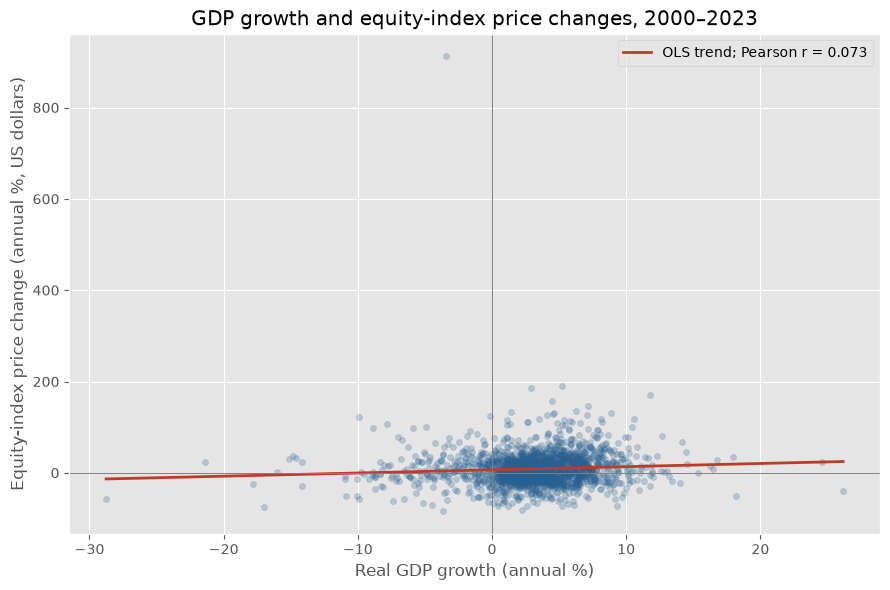

Across 1,893 matched country-years, Pearson r = 0.073 and the fitted slope is 0.69 equity percentage points per GDP percentage point.
The scatter shows a weak positive pooled association in this sample, with substantial variation around the fitted line.
This pooled association is descriptive; repeated economies, outliers, exchange rates, and global shocks can affect it.


In [14]:
x = combined["gdp_growth_pct"]
y = combined["equity_index_change_pct"]
correlation = x.corr(y)
slope, intercept = np.polyfit(x, y, 1)
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(x, y, alpha=0.25, s=18, color="#286090")
line_x = np.linspace(x.min(), x.max(), 200)
ax.plot(line_x, intercept + slope * line_x, color="#bc3c29", linewidth=2,
        label=f"OLS trend; Pearson r = {correlation:.3f}")
ax.axhline(0, color="grey", linewidth=0.7)
ax.axvline(0, color="grey", linewidth=0.7)
ax.set(title="GDP growth and equity-index price changes, 2000–2023",
       xlabel="Real GDP growth (annual %)",
       ylabel="Equity-index price change (annual %, US dollars)")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Across {len(combined):,} matched country-years, Pearson r = {correlation:.3f} "
      f"and the fitted slope is {slope:.2f} equity percentage points per GDP percentage point.")
strength = "weak" if abs(correlation) < 0.3 else "moderate" if abs(correlation) < 0.7 else "strong"
direction = "positive" if correlation > 0 else "negative" if correlation < 0 else "zero"
print(f"The scatter shows a {strength} {direction} pooled association in this sample, "
      "with substantial variation around the fitted line.")
print("This pooled association is descriptive; repeated economies, outliers, exchange rates, "
      "and global shocks can affect it.")

**Visual 2: annual medians.** The two median series show whether typical growth and price changes move together over time, including years of common shocks; the bars show how many economies contribute each year. Different sample composition across years and different indicator scales mean this figure describes timing, not a causal effect.

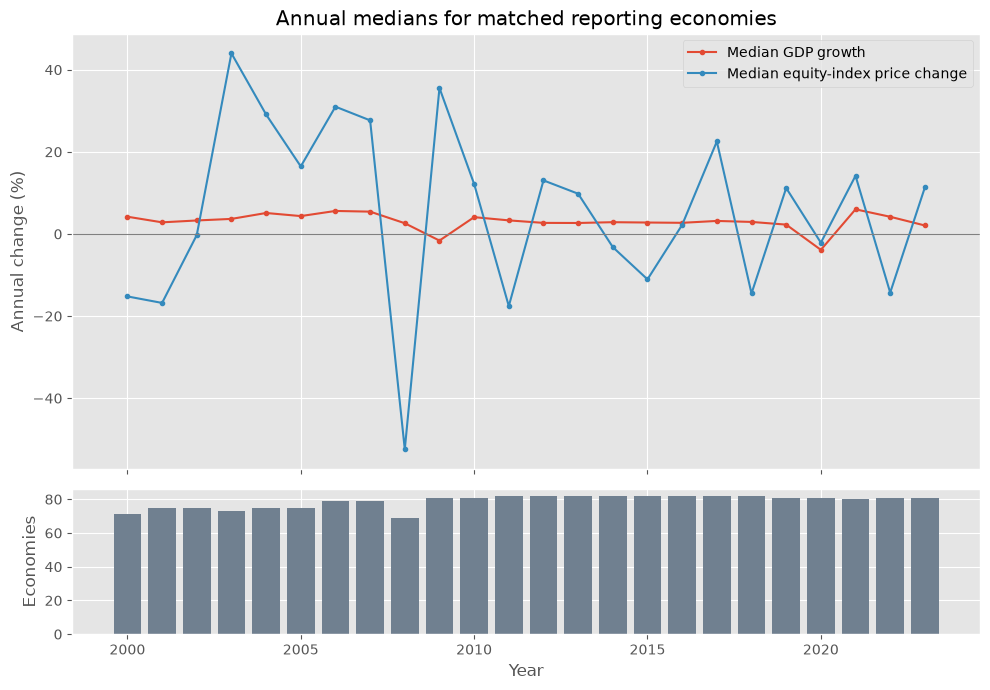

Across 24 annual medians, Pearson r = 0.117; the median indicators have the same sign in 14 years.
The annual medians show a weak positive association, describing their co-movement across years rather than causation.
The number of contributing economies ranges from 69 to 82, so changes in coverage may affect the medians.


In [15]:
annual = combined.groupby("year").agg(
    median_gdp=("gdp_growth_pct", "median"),
    median_equity=("equity_index_change_pct", "median"),
    economies=("country_code", "nunique"))
fig, (ax, count_ax) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax.plot(annual.index, annual["median_gdp"], marker="o", markersize=3,
        label="Median GDP growth")
ax.plot(annual.index, annual["median_equity"], marker="o", markersize=3,
        label="Median equity-index price change")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set(title="Annual medians for matched reporting economies",
       ylabel="Annual change (%)")
ax.legend()
count_ax.bar(annual.index, annual["economies"], color="#708090")
count_ax.set(xlabel="Year", ylabel="Economies")
plt.tight_layout()
plt.show()
median_r = annual["median_gdp"].corr(annual["median_equity"])
same_sign = (np.sign(annual["median_gdp"]) == np.sign(annual["median_equity"])).sum()
print(f"Across {len(annual)} annual medians, Pearson r = {median_r:.3f}; "
      f"the median indicators have the same sign in {same_sign} years.")
median_strength = "weak" if abs(median_r) < 0.3 else "moderate" if abs(median_r) < 0.7 else "strong"
median_direction = "positive" if median_r > 0 else "negative" if median_r < 0 else "zero"
print(f"The annual medians show a {median_strength} {median_direction} association, "
      "describing their co-movement across years rather than causation.")
print(f"The number of contributing economies ranges from {annual['economies'].min()} "
      f"to {annual['economies'].max()}, so changes in coverage may affect the medians.")

### Interpretation and limitations
Together, the scatter and annual medians answer the question with two complementary descriptions: the pooled country-year relationship and its annual context. The calculated correlations and slope appear next to the visuals; neither establishes that economic growth influences equity prices, because economies recur over time, shocks affect both series, the observations are not equally representative, and prices are expressed in US dollars. Growth data may also be revised and index coverage excludes many economies.

### 5.2 Next steps
With more time, I would examine missingness by economy and year and compare the results with a balanced panel of consistently covered economies. I would also investigate extreme values and revisions against the original sources rather than automatically discarding them. Finally, I would compare lagged GDP growth and equity returns using country and year effects, while considering currency movements and other confounders.